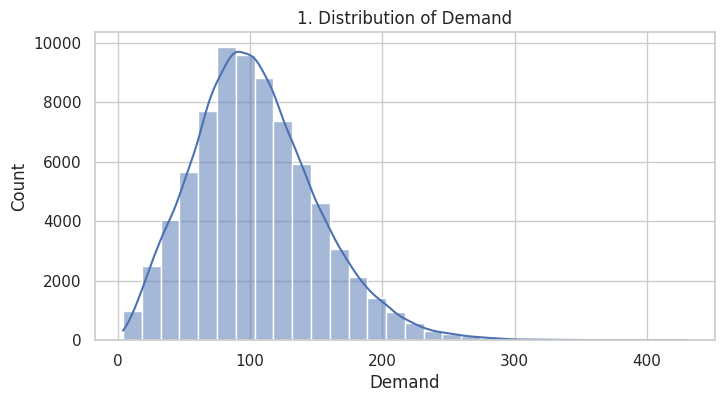

AttributeError: 'numpy.ndarray' object has no attribute 'yaxis'

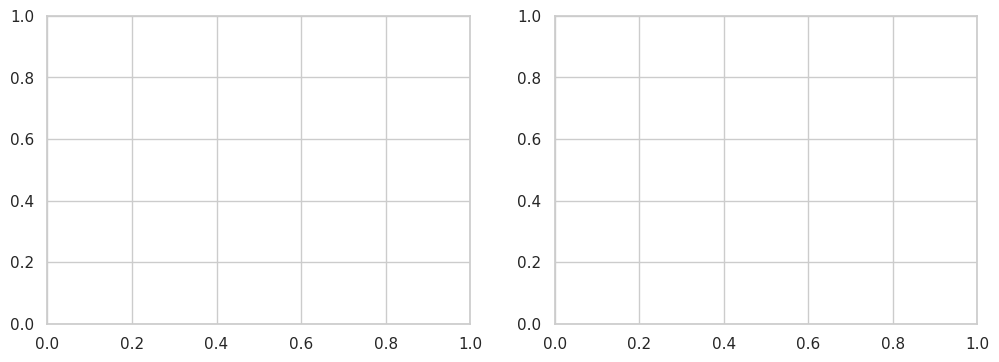

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

url = "https://raw.githubusercontent.com/awais-DS/Data/refs/heads/main/sales_data.csv"
df = pd.read_csv(url)

df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')
df['Day'] = df['Date'].dt.day
df['Day_of_Week'] = df['Date'].dt.day_name()
df['Is_Weekend'] = df['Date'].dt.dayofweek >= 5
df['Quarter'] = df['Date'].dt.quarter
df['Revenue'] = df['Units Sold'] * df['Price']

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 4))
sns.histplot(df['Demand'], kde=True, bins=30)
plt.title('1. Distribution of Demand')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Category', ax=axes)
sns.countplot(data=df, x='Region', ax=axes)
axes.set_title('2a. Category Counts')
axes.set_title('2b. Region Counts')
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=df[['Price', 'Competitor Pricing']])
plt.title('3. Price vs Competitor Pricing Spread')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='Weather Condition', ax=axes)
sns.countplot(data=df, x='Promotion', ax=axes)
sns.countplot(data=df, x='Epidemic', ax=axes)
plt.suptitle('4. Weather, Promotion, and Epidemic Frequencies')
plt.show()

daily_df = df.groupby('Date')[['Demand', 'Units Sold']].sum().reset_index()
plt.figure(figsize=(12, 4))
sns.lineplot(data=daily_df, x='Date', y='Demand', label='Demand')
sns.lineplot(data=daily_df, x='Date', y='Units Sold', label='Units Sold')
plt.title('5. Total Demand vs Units Sold Over Time')
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='Seasonality', y='Demand', hue='Category', errorbar=None)
plt.title('6. Average Demand by Season and Category')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='Promotion', y='Demand', ax=axes)
sns.boxplot(data=df, x='Epidemic', y='Demand', ax=axes)
plt.suptitle('7. Demand Distribution by Promotion & Epidemic')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=42), x='Price', y='Demand', hue='Category', alpha=0.5)
plt.title('8. Price vs Demand by Category')
plt.show()

plt.figure(figsize=(7, 6))
sample_stock = df.sample(min(2000, len(df)), random_state=42)
sns.scatterplot(data=sample_stock, x='Inventory Level', y='Demand', alpha=0.5)
max_val = max(sample_stock['Inventory Level'].max(), sample_stock['Demand'].max())
plt.plot([0, max_val], [0, max_val], 'r--', label='Stockout Line (Demand = Inventory)')
plt.legend()
plt.title('9. Inventory Level vs Demand')
plt.show()

plt.figure(figsize=(10, 8))
num_cols = df[['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Epidemic', 'Demand']]
sns.heatmap(num_cols.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('10. Numerical Feature Correlation Heatmap')
plt.show()

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x='Month', y='Demand', hue='Year', marker='o', estimator='mean', errorbar=None)
plt.title('11. Average Monthly Demand by Year')
plt.xticks(range(1, 13))
plt.show()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x='Day_of_Week', y='Demand', order=day_order, errorbar=None)
plt.title('12. Average Demand by Day of the Week')
plt.show()

plt.figure(figsize=(12, 4))
sns.lineplot(data=df, x='Day', y='Demand', estimator='mean', marker='o', errorbar=None)
plt.title('13. Average Demand by Day of the Month (1–31)')
plt.xticks(range(1, 32))
plt.show()

pivot_table = df.pivot_table(index='Day_of_Week', columns='Month', values='Demand', aggfunc='mean').reindex(day_order)
plt.figure(figsize=(11, 5))
sns.heatmap(pivot_table, cmap='YlGnBu', annot=True, fmt='.0f')
plt.title('14. Heatmap: Average Demand (Day of Week vs. Month)')
plt.show()

total_demand = df['Demand'].sum()
total_sold = df['Units Sold'].sum()
lost_sales = (df['Demand'] - df['Units Sold']).clip(lower=0).sum()
fill_rate = (total_sold / total_demand) * 100
total_revenue = df['Revenue'].sum()
promo_lift = ((df[df['Promotion'] == 1]['Demand'].mean() / df[df['Promotion'] == 0]['Demand'].mean()) - 1) * 100

fig = plt.figure(figsize=(18, 11), facecolor='#f8f9fa')
gs = gridspec.GridSpec(3, 3, height_ratios=[0.6, 1.5, 1.5], hspace=0.4, wspace=0.25)
fig.suptitle('RETAIL DEMAND & INVENTORY EDA DASHBOARD', fontsize=18, fontweight='bold', y=0.96, color='#212529')

kpis = [
    ("Total Demand", f"{total_demand:,.0f} units", "#0d6efd"),
    ("Total Revenue", f"${total_revenue:,.0f}", "#198754"),
    ("Stockout Lost Sales", f"{lost_sales:,.0f} units ({100-fill_rate:.1f}%)", "#dc3545")
]

for idx, (title, val, color) in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs[0, idx])
    ax_kpi.set_facecolor('white')
    ax_kpi.text(0.5, 0.65, title, ha='center', va='center', fontsize=12, color='#6c757d', fontweight='bold')
    ax_kpi.text(0.5, 0.30, val, ha='center', va='center', fontsize=18, color=color, fontweight='bold')
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#dee2e6')
        spine.set_linewidth(1.5)

ax1 = fig.add_subplot(gs[1, :2])
daily = df.groupby('Date')[['Demand', 'Units Sold']].sum().rolling(7).mean().reset_index()
sns.lineplot(data=daily, x='Date', y='Demand', ax=ax1, label='7-Day Avg Demand', color='#0d6efd', linewidth=2)
sns.lineplot(data=daily, x='Date', y='Units Sold', ax=ax1, label='7-Day Avg Units Sold', color='#198754', linewidth=2)
ax1.set_title('1. Demand vs. Actual Sales Trend (7-Day Moving Average)', fontweight='bold', loc='left')
ax1.set_ylabel('Units')
ax1.legend()

ax2 = fig.add_subplot(gs)
sns.barplot(data=df, x='Category', y='Demand', hue='Seasonality', ax=ax2, palette='viridis', errorbar=None)
ax2.set_title('2. Avg Demand by Category & Season', fontweight='bold', loc='left')
ax2.tick_params(axis='x', rotation=15)
ax2.legend(title='Season', fontsize=8, title_fontsize=9)

ax3 = fig.add_subplot(gs)
sns.barplot(data=df, x='Day_of_Week', y='Demand', order=day_order, ax=ax3, color='#4c72b0', errorbar=None)
ax3.set_title('3. Avg Demand by Day of Week', fontweight='bold', loc='left')
ax3.set_xlabel('')
ax3.tick_params(axis='x', rotation=30)

ax4 = fig.add_subplot(gs)
sns.boxplot(data=df, x='Promotion', y='Demand', hue='Epidemic', ax=ax4, palette='Set2')
ax4.set_title(f'4. Promo (+{promo_lift:.1f}% Lift) & Epidemic Impact', fontweight='bold', loc='left')
ax4.set_xticklabels(['No Promo (0)', 'Promo (1)'])

ax5 = fig.add_subplot(gs)
sample_df = df.sample(min(1500, len(df)), random_state=42)
sns.scatterplot(data=sample_df, x='Inventory Level', y='Demand', alpha=0.4, ax=ax5, color='#6f42c1')
max_val = max(sample_df['Inventory Level'].max(), sample_df['Demand'].max())
ax5.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Stockout Threshold')
ax5.set_title('5. Inventory vs. Demand (Stockout Check)', fontweight='bold', loc='left')
ax5.legend(fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('retail_eda_dashboard.png', dpi=300)
plt.show()


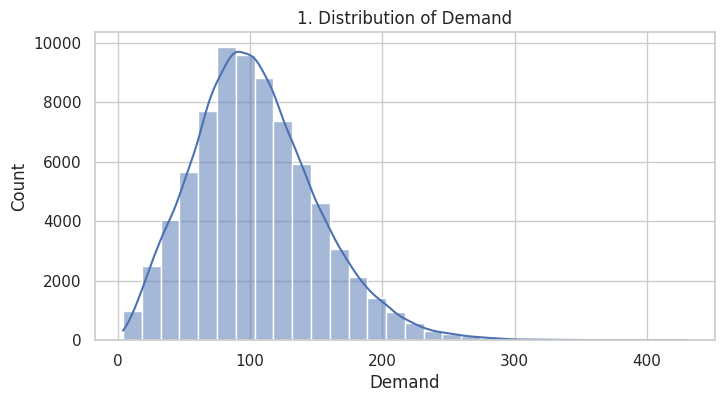

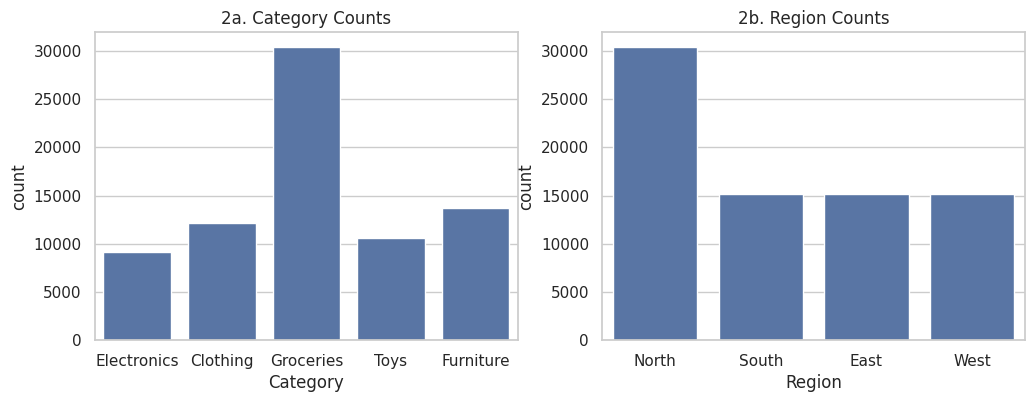

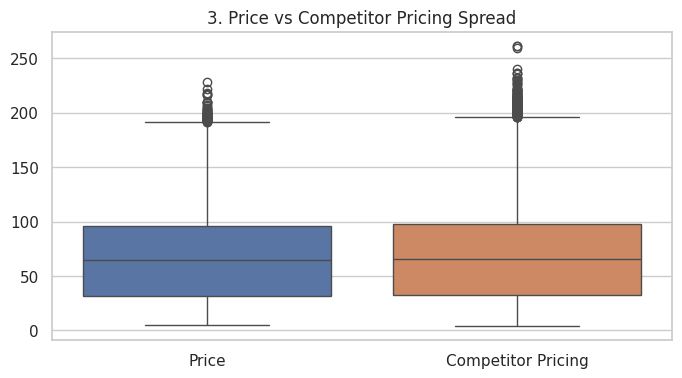

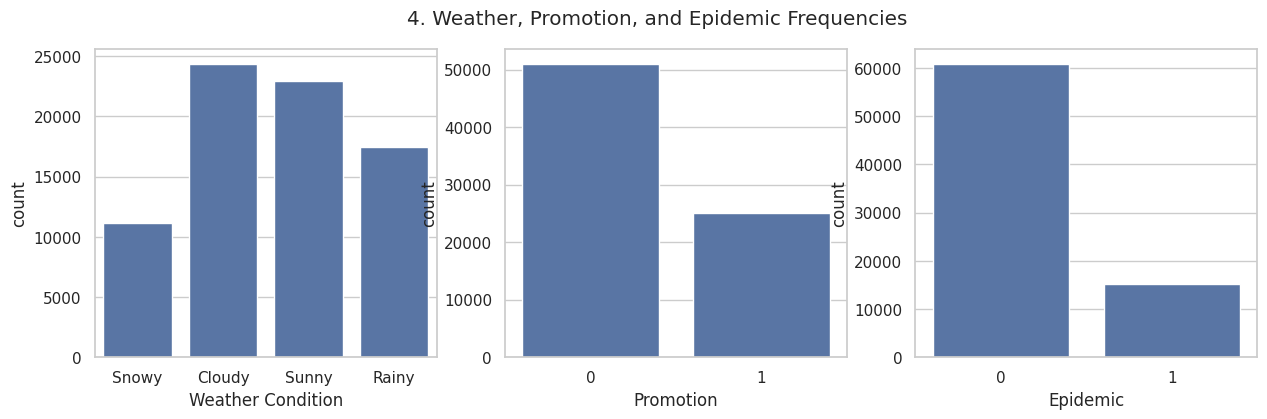

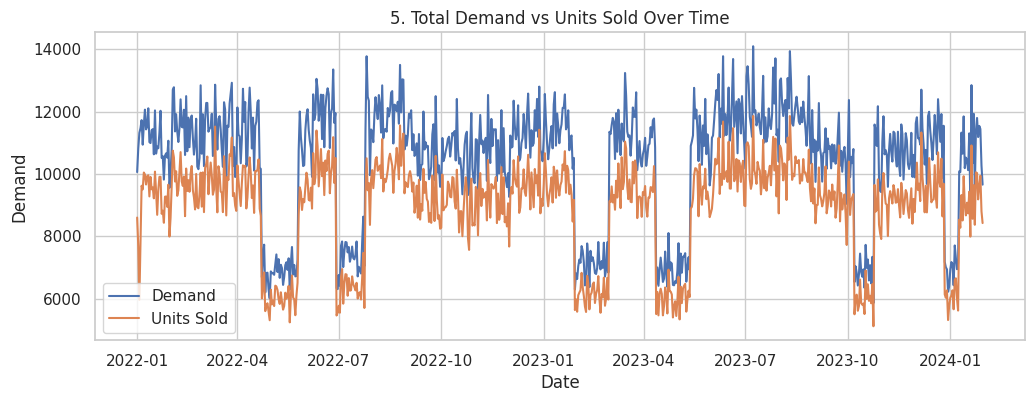

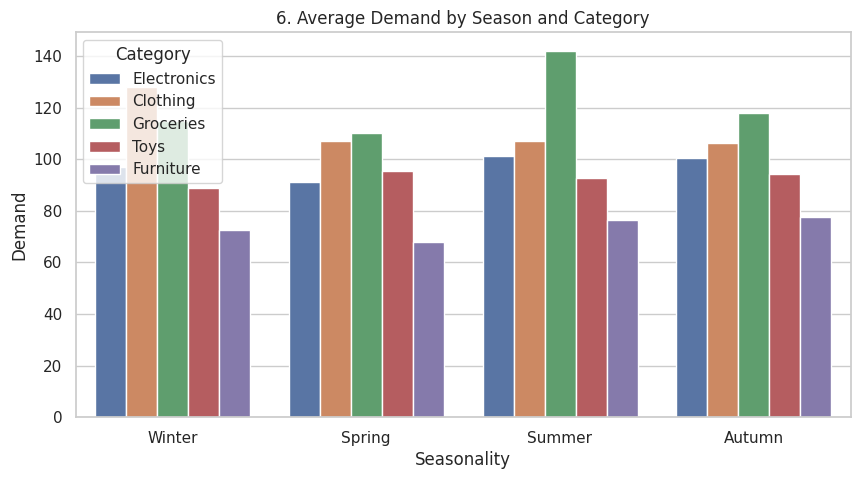

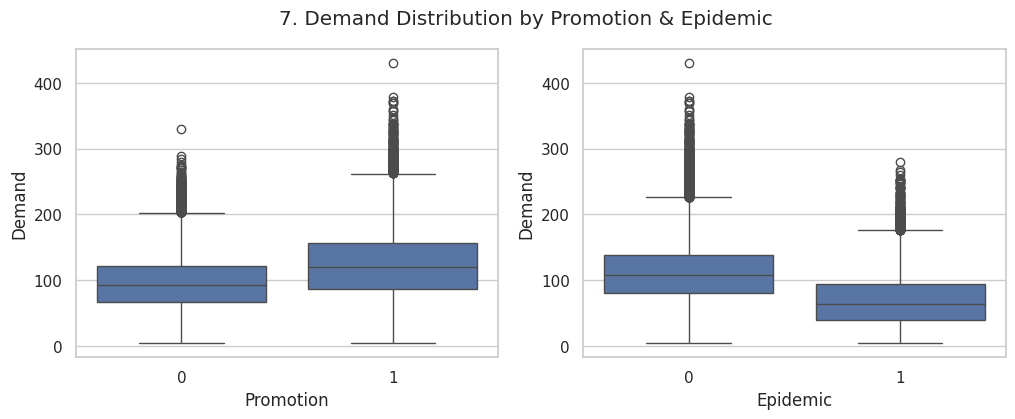

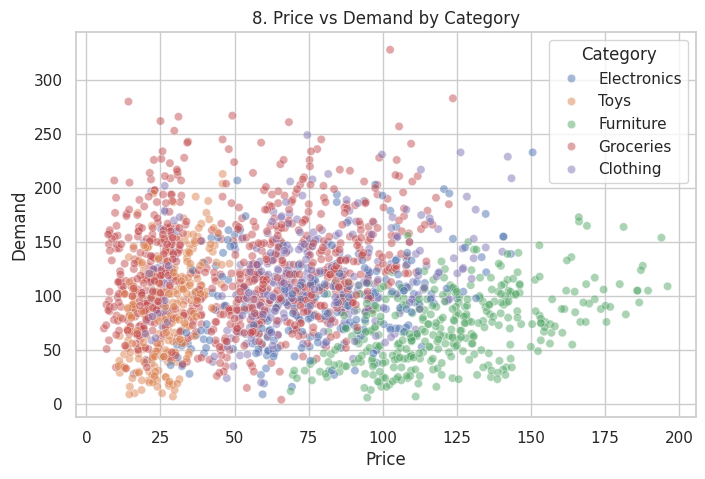

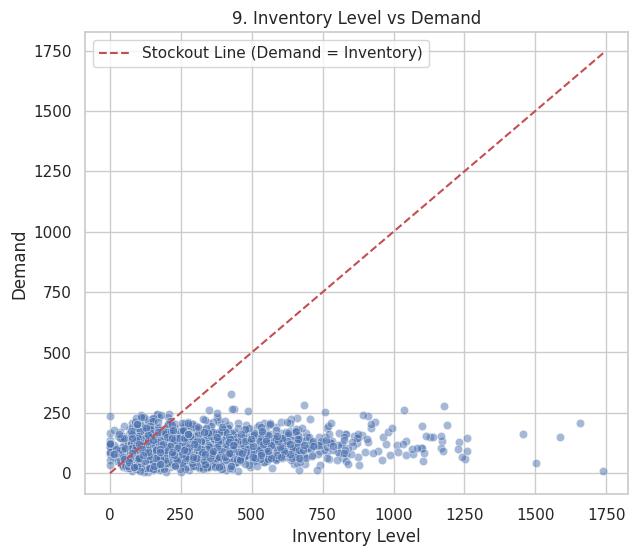

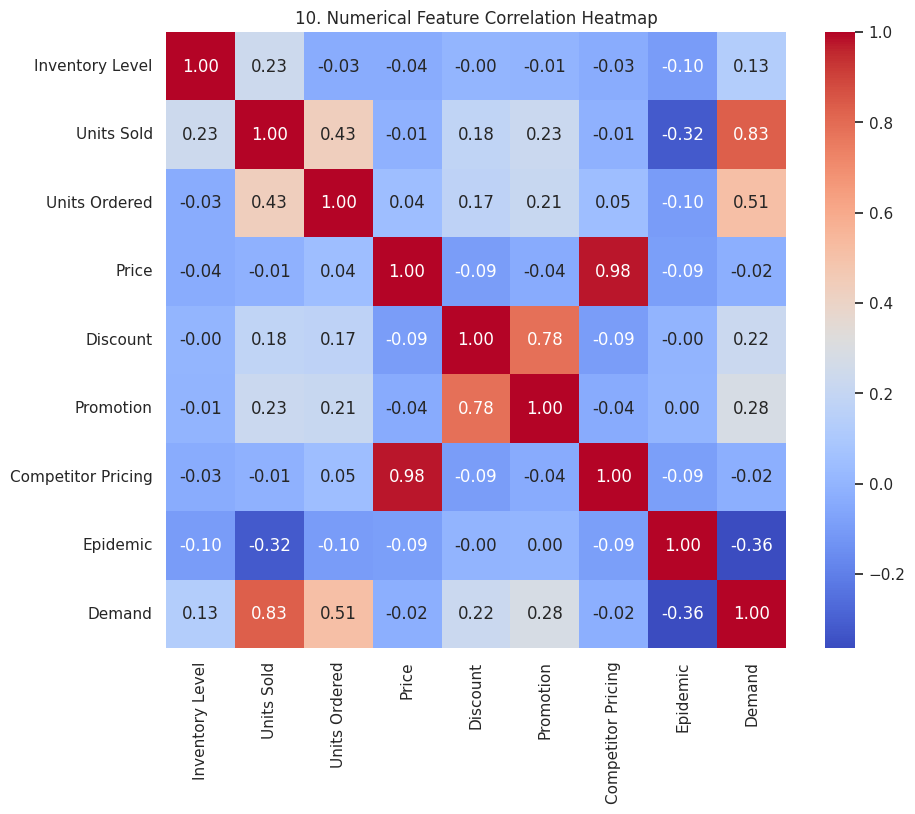

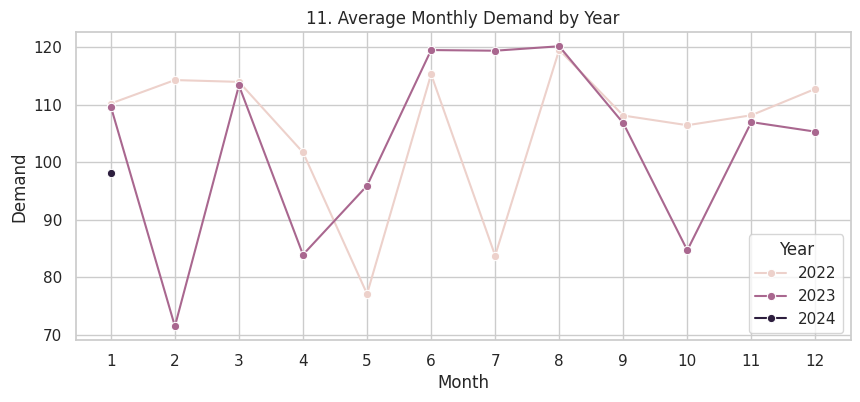

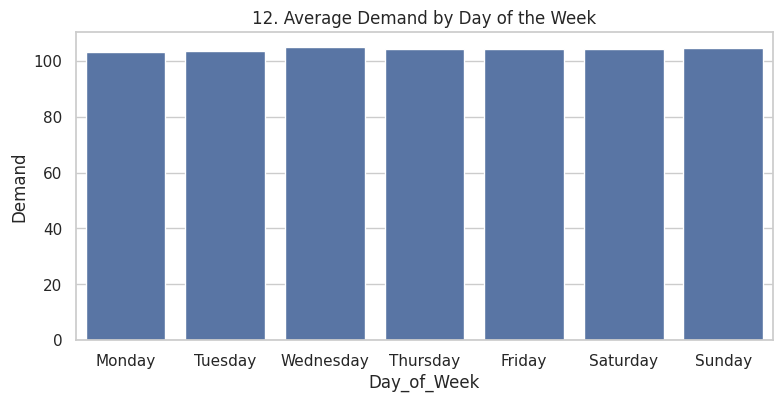

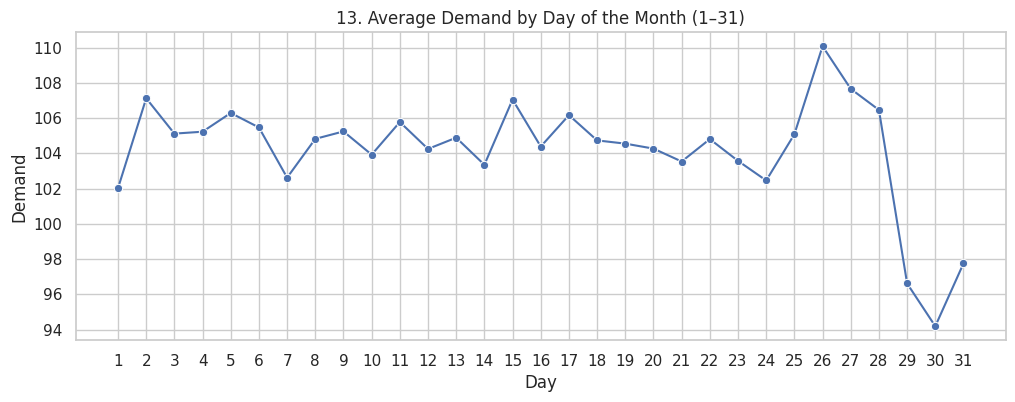

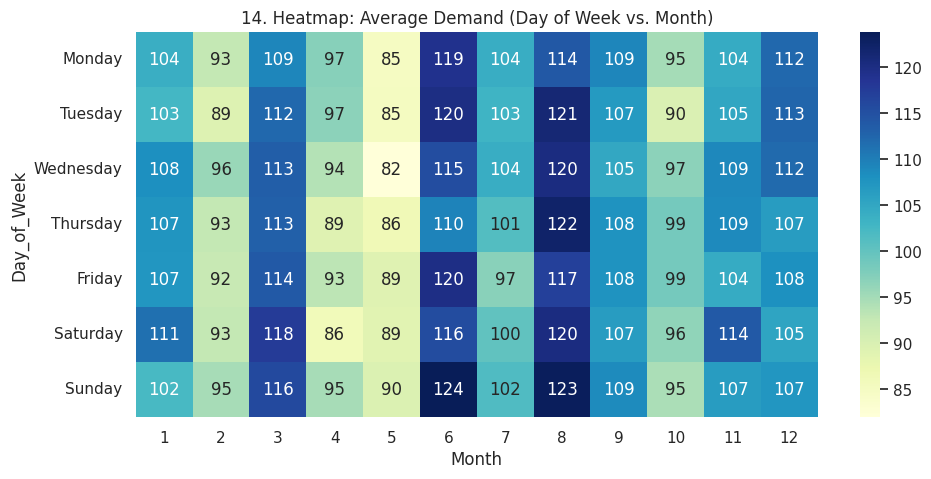

/tmp/ipykernel_3939/4210571585.py:159: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax4.set_xticklabels(['No Promo (0)', 'Promo (1)'])
/tmp/ipykernel_3939/4210571585.py:169: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.94])


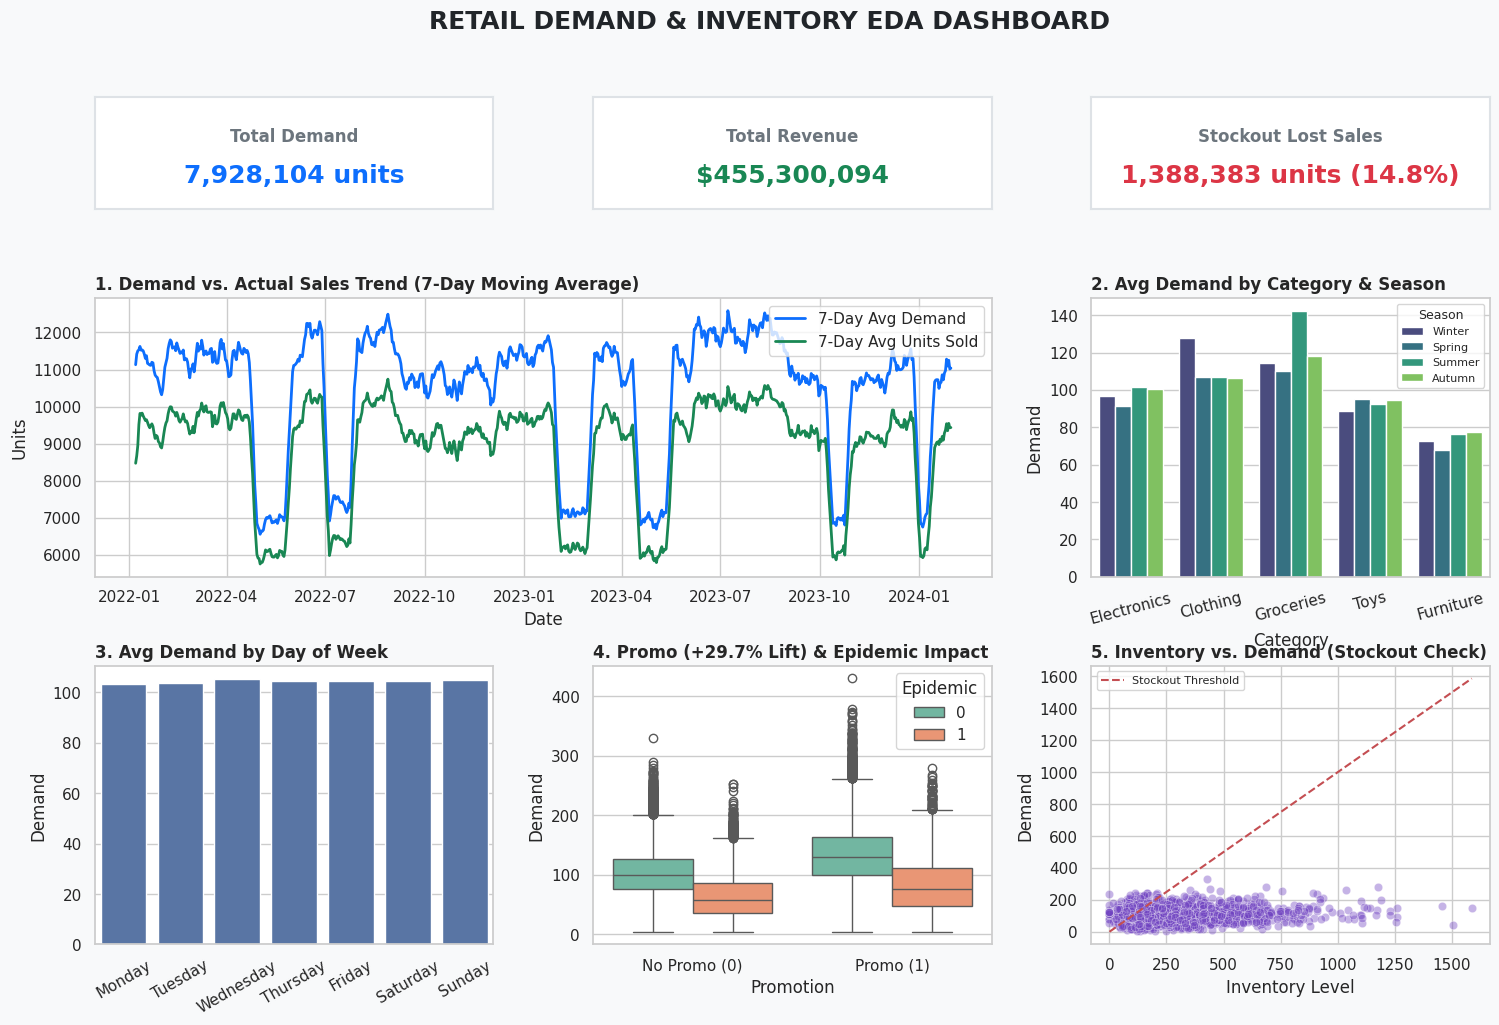

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

url = "https://raw.githubusercontent.com/awais-DS/Data/refs/heads/main/sales_data.csv"
df = pd.read_csv(url)

df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')
df['Day'] = df['Date'].dt.day
df['Day_of_Week'] = df['Date'].dt.day_name()
df['Is_Weekend'] = df['Date'].dt.dayofweek >= 5
df['Quarter'] = df['Date'].dt.quarter
df['Revenue'] = df['Units Sold'] * df['Price']

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 4))
sns.histplot(df['Demand'], kde=True, bins=30)
plt.title('1. Distribution of Demand')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Category', ax=axes[0])
sns.countplot(data=df, x='Region', ax=axes[1])
axes[0].set_title('2a. Category Counts')
axes[1].set_title('2b. Region Counts')
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=df[['Price', 'Competitor Pricing']])
plt.title('3. Price vs Competitor Pricing Spread')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='Weather Condition', ax=axes[0])
sns.countplot(data=df, x='Promotion', ax=axes[1])
sns.countplot(data=df, x='Epidemic', ax=axes[2])
plt.suptitle('4. Weather, Promotion, and Epidemic Frequencies')
plt.show()

daily_df = df.groupby('Date')[['Demand', 'Units Sold']].sum().reset_index()
plt.figure(figsize=(12, 4))
sns.lineplot(data=daily_df, x='Date', y='Demand', label='Demand')
sns.lineplot(data=daily_df, x='Date', y='Units Sold', label='Units Sold')
plt.title('5. Total Demand vs Units Sold Over Time')
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='Seasonality', y='Demand', hue='Category', errorbar=None)
plt.title('6. Average Demand by Season and Category')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='Promotion', y='Demand', ax=axes[0])
sns.boxplot(data=df, x='Epidemic', y='Demand', ax=axes[1])
plt.suptitle('7. Demand Distribution by Promotion & Epidemic')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=42), x='Price', y='Demand', hue='Category', alpha=0.5)
plt.title('8. Price vs Demand by Category')
plt.show()

plt.figure(figsize=(7, 6))
sample_stock = df.sample(min(2000, len(df)), random_state=42)
sns.scatterplot(data=sample_stock, x='Inventory Level', y='Demand', alpha=0.5)
max_val = max(sample_stock['Inventory Level'].max(), sample_stock['Demand'].max())
plt.plot([0, max_val], [0, max_val], 'r--', label='Stockout Line (Demand = Inventory)')
plt.legend()
plt.title('9. Inventory Level vs Demand')
plt.show()

plt.figure(figsize=(10, 8))
num_cols = df[['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Epidemic', 'Demand']]
sns.heatmap(num_cols.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('10. Numerical Feature Correlation Heatmap')
plt.show()

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x='Month', y='Demand', hue='Year', marker='o', estimator='mean', errorbar=None)
plt.title('11. Average Monthly Demand by Year')
plt.xticks(range(1, 13))
plt.show()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x='Day_of_Week', y='Demand', order=day_order, errorbar=None)
plt.title('12. Average Demand by Day of the Week')
plt.show()

plt.figure(figsize=(12, 4))
sns.lineplot(data=df, x='Day', y='Demand', estimator='mean', marker='o', errorbar=None)
plt.title('13. Average Demand by Day of the Month (1–31)')
plt.xticks(range(1, 32))
plt.show()

pivot_table = df.pivot_table(index='Day_of_Week', columns='Month', values='Demand', aggfunc='mean').reindex(day_order)
plt.figure(figsize=(11, 5))
sns.heatmap(pivot_table, cmap='YlGnBu', annot=True, fmt='.0f')
plt.title('14. Heatmap: Average Demand (Day of Week vs. Month)')
plt.show()

total_demand = df['Demand'].sum()
total_sold = df['Units Sold'].sum()
lost_sales = (df['Demand'] - df['Units Sold']).clip(lower=0).sum()
fill_rate = (total_sold / total_demand) * 100
total_revenue = df['Revenue'].sum()
promo_lift = ((df[df['Promotion'] == 1]['Demand'].mean() / df[df['Promotion'] == 0]['Demand'].mean()) - 1) * 100

fig = plt.figure(figsize=(18, 11), facecolor='#f8f9fa')
gs = gridspec.GridSpec(3, 3, height_ratios=[0.6, 1.5, 1.5], hspace=0.4, wspace=0.25)
fig.suptitle('RETAIL DEMAND & INVENTORY EDA DASHBOARD', fontsize=18, fontweight='bold', y=0.96, color='#212529')

kpis = [
    ("Total Demand", f"{total_demand:,.0f} units", "#0d6efd"),
    ("Total Revenue", f"${total_revenue:,.0f}", "#198754"),
    ("Stockout Lost Sales", f"{lost_sales:,.0f} units ({100-fill_rate:.1f}%)", "#dc3545")
]

for idx, (title, val, color) in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs[0, idx])
    ax_kpi.set_facecolor('white')
    ax_kpi.text(0.5, 0.65, title, ha='center', va='center', fontsize=12, color='#6c757d', fontweight='bold')
    ax_kpi.text(0.5, 0.30, val, ha='center', va='center', fontsize=18, color=color, fontweight='bold')
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#dee2e6')
        spine.set_linewidth(1.5)

ax1 = fig.add_subplot(gs[1, :2])
daily = df.groupby('Date')[['Demand', 'Units Sold']].sum().rolling(7).mean().reset_index()
sns.lineplot(data=daily, x='Date', y='Demand', ax=ax1, label='7-Day Avg Demand', color='#0d6efd', linewidth=2)
sns.lineplot(data=daily, x='Date', y='Units Sold', ax=ax1, label='7-Day Avg Units Sold', color='#198754', linewidth=2)
ax1.set_title('1. Demand vs. Actual Sales Trend (7-Day Moving Average)', fontweight='bold', loc='left')
ax1.set_ylabel('Units')
ax1.legend()

ax2 = fig.add_subplot(gs[1, 2])
sns.barplot(data=df, x='Category', y='Demand', hue='Seasonality', ax=ax2, palette='viridis', errorbar=None)
ax2.set_title('2. Avg Demand by Category & Season', fontweight='bold', loc='left')
ax2.tick_params(axis='x', rotation=15)
ax2.legend(title='Season', fontsize=8, title_fontsize=9)

ax3 = fig.add_subplot(gs[2, 0])
sns.barplot(data=df, x='Day_of_Week', y='Demand', order=day_order, ax=ax3, color='#4c72b0', errorbar=None)
ax3.set_title('3. Avg Demand by Day of Week', fontweight='bold', loc='left')
ax3.set_xlabel('')
ax3.tick_params(axis='x', rotation=30)

ax4 = fig.add_subplot(gs[2, 1])
sns.boxplot(data=df, x='Promotion', y='Demand', hue='Epidemic', ax=ax4, palette='Set2')
ax4.set_title(f'4. Promo (+{promo_lift:.1f}% Lift) & Epidemic Impact', fontweight='bold', loc='left')
ax4.set_xticklabels(['No Promo (0)', 'Promo (1)'])

ax5 = fig.add_subplot(gs[2, 2])
sample_df = df.sample(min(1500, len(df)), random_state=42)
sns.scatterplot(data=sample_df, x='Inventory Level', y='Demand', alpha=0.4, ax=ax5, color='#6f42c1')
max_val = max(sample_df['Inventory Level'].max(), sample_df['Demand'].max())
ax5.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Stockout Threshold')
ax5.set_title('5. Inventory vs. Demand (Stockout Check)', fontweight='bold', loc='left')
ax5.legend(fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('retail_eda_dashboard.png', dpi=300)
plt.show()
